<a href="https://colab.research.google.com/github/marreapato/Deep_Learning_Course/blob/main/Simple_ML_imageclass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Step 1: Load the MNIST dataset (grayscale, 28x28)
(x_train, y_train), (x_test, y_test) = mnist.load_data()



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [2]:
# Step 2: Flatten and normalize the images
x_train_flat = x_train.reshape((x_train.shape[0], -1)) / 255.0
x_test_flat = x_test.reshape((x_test.shape[0], -1)) / 255.0

# Optional: Use only a subset for speed (e.g., 10k train, 1k test)
x_train_flat, _, y_train, _ = train_test_split(x_train_flat, y_train, train_size=10000, stratify=y_train, random_state=42)
x_test_flat, _, y_test, _ = train_test_split(x_test_flat, y_test, test_size=1000, stratify=y_test, random_state=42)



In [3]:
# Step 3: Train a classifier (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train_flat, y_train)



RandomForestClassifier(random_state=42)

In [4]:
# Step 4: Evaluate on test set
y_pred = model.predict(x_test_flat)

print("✅ Accuracy:", accuracy_score(y_test, y_pred))
print("\n📊 Classification Report:\n", classification_report(y_test, y_pred))



✅ Accuracy: 0.9518888888888889

📊 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97       882
           1       0.98      0.99      0.98      1021
           2       0.95      0.95      0.95       929
           3       0.94      0.94      0.94       909
           4       0.96      0.95      0.95       884
           5       0.96      0.94      0.95       803
           6       0.96      0.97      0.96       862
           7       0.96      0.94      0.95       925
           8       0.95      0.92      0.94       877
           9       0.91      0.93      0.92       908

    accuracy                           0.95      9000
   macro avg       0.95      0.95      0.95      9000
weighted avg       0.95      0.95      0.95      9000



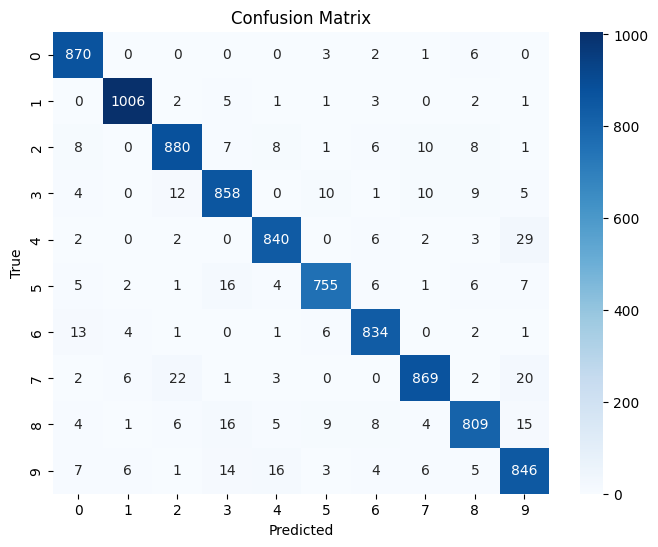

In [5]:
# Optional: Show confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [6]:
# Step 5: Save predictions to CSV (optional)
output_df = pd.DataFrame(x_test_flat)
output_df['true_label'] = y_test
output_df['predicted_label'] = y_pred
output_df

,0,1,2,3,4,5,6,7,8,9,...,776,777,778,779,780,781,782,783,true_label,predicted_label
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9,9
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6,6
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6,6
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,2
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8,8
8996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8,8
8997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6,6
8998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
